# Data Preparation and Preprocessing

## General Settings

All necessary python packages are imported and global options are set right at the beginning.

In [150]:
import os
import joblib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import MinMaxScaler

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", None)
pd.set_option("future.no_silent_downcasting", True)

plt.style.use("dark_background")

## Import and Load

Load the raw data from the *Parametric Analysis* Sheet of an Excel file into a Pandas data frame using the Openpyxl engine. Skip the first two rows of the Excel sheet, as they do not contain any relevant information anyway.

In [151]:
raw_data_path = os.path.join(
    os.path.dirname(os.getcwd()), "..", "data", "raw", "MCDI_Overview_10-04-2025.xlsx"
)

df = pd.read_excel(
    raw_data_path,
    sheet_name="Parametric Analysis",
    engine="calamine",
    skiprows=2,
    dtype=str,
)

df.head()

,Unnamed: 0,Test #,Mol.\r\n(g/L),H2O\r\n,pH\r\n,Time\r\n(s),Flow\r\n (L/min),Volt. Lim.\r\n(V),Curr. Lim.\r\n(A),Check,EC In \r\n(mS/cm),EC In Dev. (%),EC Pure\r\n(mS/cm),Remov. \r\n(%),SEC \r\n(kWh/m³),Spalte1,Ry \r\n(%),Min EC Pure (mS/cm),Max. Remov. (%),Avg. EC In (mS/cm),Avg. EC Pure (mS/cm),pH Pure,pH Conc.,Test Remarks,Unnamed: 24,Unnamed: 25
0,0 - General Tests,0.1,1,DI,-,95/15/80,"0,45/0,5/0,5","1,95/1,5/1,5",60/50/55,Valid,4.42,0.014712438698172054,1.28,71,-,NaN,40,0.082,98.1,4.06,0.09,-,-,Met all the criterias.,NaN,NaN
1,NaN,0.2,1,DI,-,95/15/80,"0,35/0,4/0,4","1,95/1,5/1,5",60/50/55,Valid,4.21,0.06152474364690143,1.82,57,-,NaN,41,0.134,96.8,4.15,0.16,-,-,NaN,NaN,NaN
2,NaN,0.3,1,DI,-,95/15/80,"0,3/0,3/0,3","1,95/1,5/1,5",60/50/55,Valid,4.15,0.07489968791796688,2.36,43,-,NaN,37,0.202,95.1,4.11,0.24,-,-,NaN,NaN,NaN
3,NaN,0.4,1,DI,-,95/15/80,"0,25/0,25/0,25","1,95/1,5/1,5",60/50/55,Valid,4.13,0.07935800267498883,2.98,28,13.81,0.08312816799420708,41,0.285,93.1,4.1,0.29,-,-,NaN,NaN,NaN
4,NaN,0.5,1,DI,-,95/15/80,"0,25/0,25/0,25","1,9/1,9/1,9",60/50/55,Valid,4.11,0.08381631743201058,3.08,25,-,NaN,37,0.285,93.1,4.08,0.3,-,-,NaN,NaN,NaN


## Clean

### Basic Steps

As you can see, the imported data frame is quite unstructured due to being exported from an Excel file that is easy for humans to read. Therefore, you need to take a few steps to bring the data frame into a processable form:

1. Rename German identifiers to English identifiers and use despriptive names.
2. Delete undefined columns.
3. Assign each measurement to a measurement series.
4. Define the validity column as the first data column so that you can quickly see whether a data point represents a valid measurement.

In [ ]:
# Local helper function
def move_column(df, col_name, new_position):
    cols = list(df.columns)
    cols.insert(new_position, cols.pop(cols.index(col_name)))
    return df[cols]


# 1. Rename columns
df.rename(
    columns={
        "Unnamed: 0": "Series",
        "Test #": "Measurement",
        "Mol.\r\n(g/L)": "Molarity (g/l)",
        "H2O\r\n": "Water Type",
        "pH\r\n": "pH-Level (pH)",
        "Time\r\n(s)": "Time (s)",
        "Flow\r\n (L/min)": "Flow (l/min)",
        "Volt. Lim.\r\n(V)": "Voltage Limit (V)",
        "Curr. Lim.\r\n(A)": "Current Limit (A)",
        "Check": "Validity",
        "EC In \r\n(mS/cm)": "Electrical Conductivity Inlet (mS/cm)",
        "EC In Dev. (%)": "Electrical Conductivity Inlet (%)",
        "EC Pure\r\n(mS/cm)": "Electrical Conductivity Pure (mS/cm)",
        "Remov. \r\n(%)": "Average Salt Removal (%)",
        "SEC \r\n(kWh/m^3)": "Specific Energy Consumption (kWh/m^3)",
        "Spalte1": "Undefined",
        "Ry \r\n(%)": "Average Water Recovery (%)",
        "Min EC Pure (mS/cm)": "Minimum Electrical Conductivity Pure (mS/cm)",
        "Max. Remov. (%)": "Maximum Salt Removal (%)",
        "Avg. EC In (mS/cm)": "Average Electrical Conductivity Inlet (mS/cm)",
        "Avg. EC Pure (mS/cm)": "Average Electrical Conductivity Pure (mS/cm)",
        "pH Pure": "pH-Level Pure (pH)",
        "pH Conc. ": "pH-Level Concentrate (pH)",
        "Test Remarks ": "Undefined",
        "Unnamed: 24": "Undefined",
        "Unnamed: 25": "Undefined",
    },
    inplace=True,
)

# 2. Delete columns that are undefined
df.drop(columns=["Undefined"], inplace=True)
df.drop(df.tail(2).index, inplace=True)

# 3. Fill series column
df["Series"] = df["Series"].ffill()

# 4. Move validity column to be the third column
df = move_column(df, "Validity", 2)

df.head()

,Series,Measurement,Validity,Molarity (g/l),Water Type,pH-Level (pH),Time (s),Flow (l/min),Voltage Limit (V),Current Limit (A),Electrical Conductivity Inlet (mS/cm),Electrical Conductivity Inlet (%),Electrical Conductivity Pure (mS/cm),Average Salt Removal (%),SEC \r\n(kWh/m³),Average Water Recovery (%),Minimum Electrical Conductivity Pure (mS/cm),Maximum Salt Removal (%),Average Electrical Conductivity Inlet (mS/cm),Average Electrical Conductivity Pure (mS/cm),pH-Level Pure (pH),pH-Level Concentrate (pH)
0,0 - General Tests,0.1,Valid,1,DI,-,95/15/80,"0,45/0,5/0,5","1,95/1,5/1,5",60/50/55,4.42,0.014712438698172054,1.28,71,-,40,0.082,98.1,4.06,0.09,-,-
1,0 - General Tests,0.2,Valid,1,DI,-,95/15/80,"0,35/0,4/0,4","1,95/1,5/1,5",60/50/55,4.21,0.06152474364690143,1.82,57,-,41,0.134,96.8,4.15,0.16,-,-
2,0 - General Tests,0.3,Valid,1,DI,-,95/15/80,"0,3/0,3/0,3","1,95/1,5/1,5",60/50/55,4.15,0.07489968791796688,2.36,43,-,37,0.202,95.1,4.11,0.24,-,-
3,0 - General Tests,0.4,Valid,1,DI,-,95/15/80,"0,25/0,25/0,25","1,95/1,5/1,5",60/50/55,4.13,0.07935800267498883,2.98,28,13.81,41,0.285,93.1,4.1,0.29,-,-
4,0 - General Tests,0.5,Valid,1,DI,-,95/15/80,"0,25/0,25/0,25","1,9/1,9/1,9",60/50/55,4.11,0.08381631743201058,3.08,25,-,37,0.285,93.1,4.08,0.3,-,-


### Split Columns with multiple Values

5. The columns `Time`, `Flow`, `Voltage Limit`, and `Current Limit` each show a total of three values for the three different phases. These values are now divided into three separate columns (Concentrate - C, Pre-Purify - PP, Purify - P) so that the values can be processed more easily later. 
6. The notation of values containing a comma is changed to the dot notation.

In [153]:
# Local helper function
def split_column(df, column_name, new_column_names, separator):
    df[new_column_names] = df[column_name].str.split(separator, expand=True)
    df.drop(columns=column_name, inplace=True)
    return df


# 5. Split columns with multiple values
df = split_column(df, "Time (s)", ["Time_C (s)", "Time_PP (s)", "Time_P (s)"], "/")
df = split_column(
    df, "Flow (l/min)", ["Flow_C (l/min)", "Flow_PP (l/min)", "Flow_P (l/min)"], "/"
)
df = split_column(
    df,
    "Voltage Limit (V)",
    ["Voltage_Limit_C (V)", "Voltage_Limit_PP (V)", "Voltage_Limit_P (V)"],
    "/",
)
df = split_column(
    df,
    "Current Limit (A)",
    ["Current_Limit_C (A)", "Current_Limit_PP (A)", "Current_Limit_P (A)"],
    "/",
)

# 6. Replace commas with dots in object columns
for col in df.select_dtypes(include=["object"]).columns:
    df[col] = df[col].str.replace(",", ".", regex=False)

display(df.head(3))
display(df.dtypes)

,Series,Measurement,Validity,Molarity (g/l),Water Type,pH-Level (pH),Electrical Conductivity Inlet (mS/cm),Electrical Conductivity Inlet (%),Electrical Conductivity Pure (mS/cm),Average Salt Removal (%),SEC \r\n(kWh/m³),Average Water Recovery (%),Minimum Electrical Conductivity Pure (mS/cm),Maximum Salt Removal (%),Average Electrical Conductivity Inlet (mS/cm),Average Electrical Conductivity Pure (mS/cm),pH-Level Pure (pH),pH-Level Concentrate (pH),Time_C (s),Time_PP (s),Time_P (s),Flow_C (l/min),Flow_PP (l/min),Flow_P (l/min),Voltage_Limit_C (V),Voltage_Limit_PP (V),Voltage_Limit_P (V),Current_Limit_C (A),Current_Limit_PP (A),Current_Limit_P (A)
0,0 - General Tests,0.1,Valid,1,DI,-,4.42,0.014712438698172054,1.28,71,-,40,0.082,98.1,4.06,0.09,-,-,95,15,80,0.45,0.5,0.5,1.95,1.5,1.5,60,50,55
1,0 - General Tests,0.2,Valid,1,DI,-,4.21,0.06152474364690143,1.82,57,-,41,0.134,96.8,4.15,0.16,-,-,95,15,80,0.35,0.4,0.4,1.95,1.5,1.5,60,50,55
2,0 - General Tests,0.3,Valid,1,DI,-,4.15,0.07489968791796688,2.36,43,-,37,0.202,95.1,4.11,0.24,-,-,95,15,80,0.3,0.3,0.3,1.95,1.5,1.5,60,50,55


Series                                           object
Measurement                                      object
Validity                                         object
Molarity (g/l)                                   object
Water Type                                       object
pH-Level (pH)                                    object
Electrical Conductivity Inlet (mS/cm)            object
Electrical Conductivity Inlet (%)                object
Electrical Conductivity Pure (mS/cm)             object
Average Salt Removal (%)                         object
SEC \r\n(kWh/m³)                                 object
Average Water Recovery (%)                       object
Minimum Electrical Conductivity Pure (mS/cm)     object
Maximum Salt Removal (%)                         object
Average Electrical Conductivity Inlet (mS/cm)    object
Average Electrical Conductivity Pure (mS/cm)     object
pH-Level Pure (pH)                               object
pH-Level Concentrate (pH)                       

### Set correct Data Types

You can see here that some columns are still of type *object*, which is unsuitable for mathematical processing.

7. In order to set the correct data types for the columns, you must first set all non-existent values to *Not a Number*.
8. As the final step in the cleaning phase, all data types are selected appropriately.

In [154]:
# Local helper list
except_columns = [
    "Series",
    "Measurement",
    "Water Type",
    "Validity",
]

# 7. Replace non-existing values with NaN
df.replace("-", np.nan, inplace=True)
df.replace("", np.nan, inplace=True)

# 8. Set correct data types
cols = df.select_dtypes(include="object").columns
cols = cols.drop(except_columns)
df[cols] = df[cols].astype("float")

display(df.head(3))
display(df.info())

,Series,Measurement,Validity,Molarity (g/l),Water Type,pH-Level (pH),Electrical Conductivity Inlet (mS/cm),Electrical Conductivity Inlet (%),Electrical Conductivity Pure (mS/cm),Average Salt Removal (%),SEC \r\n(kWh/m³),Average Water Recovery (%),Minimum Electrical Conductivity Pure (mS/cm),Maximum Salt Removal (%),Average Electrical Conductivity Inlet (mS/cm),Average Electrical Conductivity Pure (mS/cm),pH-Level Pure (pH),pH-Level Concentrate (pH),Time_C (s),Time_PP (s),Time_P (s),Flow_C (l/min),Flow_PP (l/min),Flow_P (l/min),Voltage_Limit_C (V),Voltage_Limit_PP (V),Voltage_Limit_P (V),Current_Limit_C (A),Current_Limit_PP (A),Current_Limit_P (A)
0,0 - General Tests,0.1,Valid,1.0,DI,NaN,4.42,0.014712,1.28,71.0,NaN,40.0,0.082,98.1,4.06,0.09,NaN,NaN,95.0,15.0,80.0,0.45,0.5,0.5,1.95,1.5,1.5,60.0,50.0,55.0
1,0 - General Tests,0.2,Valid,1.0,DI,NaN,4.21,0.061525,1.82,57.0,NaN,41.0,0.134,96.8,4.15,0.16,NaN,NaN,95.0,15.0,80.0,0.35,0.4,0.4,1.95,1.5,1.5,60.0,50.0,55.0
2,0 - General Tests,0.3,Valid,1.0,DI,NaN,4.15,0.074900,2.36,43.0,NaN,37.0,0.202,95.1,4.11,0.24,NaN,NaN,95.0,15.0,80.0,0.30,0.3,0.3,1.95,1.5,1.5,60.0,50.0,55.0


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 65 entries, 0 to 64
Data columns (total 30 columns):
 #   Column                                         Non-Null Count  Dtype  
---  ------                                         --------------  -----  
 0   Series                                         65 non-null     object 
 1   Measurement                                    65 non-null     object 
 2   Validity                                       65 non-null     object 
 3   Molarity (g/l)                                 65 non-null     float64
 4   Water Type                                     65 non-null     object 
 5   pH-Level (pH)                                  47 non-null     float64
 6   Electrical Conductivity Inlet (mS/cm)          65 non-null     float64
 7   Electrical Conductivity Inlet (%)              42 non-null     float64
 8   Electrical Conductivity Pure (mS/cm)           65 non-null     float64
 9   Average Salt Removal (%)                       65 non-nu

None

# Incorporate Expert Knowledge

At this point, the specialist knowledge of the senior doctoral student and his team who are maintaining the facility is used to specifically exclude certain data points so that the results are not distorted by incorrect values.

The following measurements are excluded:
1. All measured values marked as invalid.
2. Measurements whose molarity in g/l is below 0.5.
3. Measurements in which distilled water was not used.
4. The entire fourth series of measurements, as the pH value fluctuates too much in this series.
5. All measurements whose phase times deviate from *155/45/120*, as otherwise the comparability of the measurements is lost.

Unfortunately, this step also means that the number of data points is drastically reduced from 65 to just 26 due to the influence of expert knowledge about the experiments.

In [155]:
print("Dataframe shape before filtering:")
display(df.shape[0])

# 1. Drop all measurements that are not valid
df = df[df["Validity"] == "Valid"]

# 2. Drop all measurements with Mol.\n(g/L) unequal to 0.5
df = df[df["Molarity (g/l)"] == 0.5]

# 3. Drop all measurements with H2O unequal to DI
df = df[df["Water Type"] == "DI"]

# 4. Drop the 4th measurement series
df = df[df["Series"] != "4 -  pH Series"]

# 5. Drop all measurements with a time in seconds unequal to 155/45/120
df = df[df["Time_C (s)"] == 155]
df = df[df["Time_PP (s)"] == 45]
df = df[df["Time_P (s)"] == 120]

print("Dataframe shape after filtering:")
display(df.shape[0])

Dataframe shape before filtering:


65

Dataframe shape after filtering:


26

## Transform

In this step, the data is transformed to ensure the best possible comparability. To do this, the data is first normalized:
1. One-Hot encoding ist used for all categorical features (here only the water type).
3. Replace *NaN* values column with the mean value of the remaining values from the respective column.
2. Min-Max normalization for all values except percentage values is used.
4. Drop duplicates if there are any. In addition, the Flow_PP column is deleted because the values in this column completely overlap with the values from the Flow_P column.

Depending on the application, standardization may also be necessary/useful at this point in the future, for example, if gradient-based algorithms are used.

In [ ]:
# Local helper lists
normalize_columns_used_min_max = [
    "Flow_C (l/min)",
    "Flow_P (l/min)",
    "Current_Limit_P (A)",
]
normalize_columns_unused_min_max = [
    "Molarity (g/l)",
    "pH-Level (pH)",
    "Time_C (s)",
    "Time_PP (s)",
    "Time_P (s)",
    "Flow_PP (l/min)",
    "Voltage_Limit_C (V)",
    "Voltage_Limit_PP (V)",
    "Voltage_Limit_P (V)",
    "Current_Limit_C (A)",
    "Current_Limit_PP (A)",
]
normalize_columns_percentage = [
    "Average Salt Removal (%)",
    "Average Water Recovery (%)",
    "Maximum Salt Removal (%)",
]

# 1. One-Hot encoding for water type feature
one_hot_water_type = pd.get_dummies(df["Water Type"])
df = pd.concat([df, one_hot_water_type], axis=1)
df = df.drop(columns=["Water Type"])

# 2. Fill NaN values in pH-Level column with mean of the column
df = df.fillna(df.mean(numeric_only=True))

# 3. Min-Max normalization for all columns except percentage columns
# Scaler are split up into used and unused columns, to reuse the first one later on
scaler_used_cols = MinMaxScaler()
df[normalize_columns_used_min_max] = scaler_used_cols.fit_transform(
    df[normalize_columns_used_min_max]
)
scaler_unused_cols = MinMaxScaler()
df[normalize_columns_unused_min_max] = scaler_unused_cols.fit_transform(
    df[normalize_columns_unused_min_max]
)

# 4. Normalize percentage columns
df[normalize_columns_percentage] = df[normalize_columns_percentage].clip(0, 100) / 100

# 5. Drop duplicates
df.drop_duplicates(inplace=True)
df.drop(columns=["Flow_PP (l/min)"])

df.head()

,Series,Measurement,Validity,Molarity (g/l),pH-Level (pH),Electrical Conductivity Inlet (mS/cm),Electrical Conductivity Inlet (%),Electrical Conductivity Pure (mS/cm),Average Salt Removal (%),SEC \r\n(kWh/m³),Average Water Recovery (%),Minimum Electrical Conductivity Pure (mS/cm),Maximum Salt Removal (%),Average Electrical Conductivity Inlet (mS/cm),Average Electrical Conductivity Pure (mS/cm),pH-Level Pure (pH),pH-Level Concentrate (pH),Time_C (s),Time_PP (s),Time_P (s),Flow_C (l/min),Flow_PP (l/min),Flow_P (l/min),Voltage_Limit_C (V),Voltage_Limit_PP (V),Voltage_Limit_P (V),Current_Limit_C (A),Current_Limit_PP (A),Current_Limit_P (A),DI
10,1 - Pre-Optimization 0.5,1.1,Valid,0.0,0.56381,3.20,0.032867,0.12,0.96,9.86,0.36,0.058,0.982,3.2000,0.0600,6.492857,8.031905,0.0,0.0,0.0,0.4,0.454545,0.454545,0.0,0.0,0.0,1.0,1.0,1.0,True
11,1 - Pre-Optimization 0.5,1.2,Valid,0.0,0.56381,3.35,0.012467,0.19,0.95,12.04,0.36,0.080,0.977,3.2000,0.0800,6.492857,8.031905,0.0,0.0,0.0,0.2,0.272727,0.272727,0.0,0.0,0.0,1.0,1.0,1.0,True
12,1 - Pre-Optimization 0.5,1.3,Valid,0.0,0.56381,3.53,0.066868,0.33,0.89,14.70,0.34,0.111,0.966,3.4000,0.1200,6.492857,8.031905,0.0,0.0,0.0,0.1,0.090909,0.090909,0.0,0.0,0.0,1.0,1.0,1.0,True
13,1 - Pre-Optimization 0.5,1.4,Valid,0.0,0.56381,3.61,0.091046,0.52,0.83,17.08,0.33,0.143,0.956,3.5000,0.1600,6.492857,8.031905,0.0,0.0,0.0,0.0,0.000000,0.000000,0.0,0.0,0.0,1.0,1.0,1.0,True
14,1 - Pre-Optimization 0.5,1.5,Valid,0.0,0.56381,3.26,0.014734,0.10,0.97,8.26,0.36,0.049,0.985,2.4664,0.1112,6.492857,8.031905,0.0,0.0,0.0,0.6,0.636364,0.636364,0.0,0.0,0.0,1.0,1.0,1.0,True


## Restructure into Input and Output Data

The input data is now packaged in a separate data frame so that it can be analyzed and exported for further processing. The output data removal and recovery are also stored in a separate data frame. The input variables flow for all three phases and the maximum current for phase P were initially selected as the only input variables, as they are particularly easy to adjust in the system.

In [157]:
df_input_data = df[
    ["Series", "Measurement", "Flow_C (l/min)", "Flow_P (l/min)", "Current_Limit_P (A)"]
]

df_output_data_avg_removal = df[["Series", "Measurement", "Average Salt Removal (%)"]]
df_output_data_avg_recovery = df[
    ["Series", "Measurement", "Average Water Recovery (%)"]
]

## Validation of preprocessed Data

This is the first validation phase, which takes place before the data is used for a model or optimization, in order to identify potentially erroneous data at an early stage.

- Display general information about the data to get a good overview. This is useful for quickly checking whether values are outside a permitted range and whether there are the same number of data points for each value. 

- Relationships between the input variables and the output variables are then displayed for both output variables using a scatter plot. For the output variable *Average Salt Removal* a slightly exponential relationship with the two flow variables emerges. The input variable *Current Limit*, on the other hand, shows no discernible relationship with either output variable.

- The distribution of the data points can best be evaluated using a histogram and box plots. The first thing that stands out here is that the two different output variables have a very small spread, which is evident from the small size of the boxes in the box plot and the two peaks in the histogram. Otherwise, the two *Flows* have a very similar range of values, with the *Current Limit* standing out slightly with a box that is shifted significantly upwards.

,count,mean,std,min,25%,50%,75%,max
Flow_C (l/min),26.0,0.573077,0.275038,0.00,0.400000,0.600000,0.775000,1.00
Flow_P (l/min),26.0,0.604895,0.264659,0.00,0.454545,0.636364,0.795455,1.00
Current_Limit_P (A),26.0,0.653846,0.394189,0.00,0.500000,0.750000,1.000000,1.00
Average Salt Removal (%),26.0,0.961538,0.033189,0.83,0.962500,0.970000,0.980000,0.99
Average Water Recovery (%),26.0,0.334615,0.012077,0.32,0.330000,0.330000,0.340000,0.36


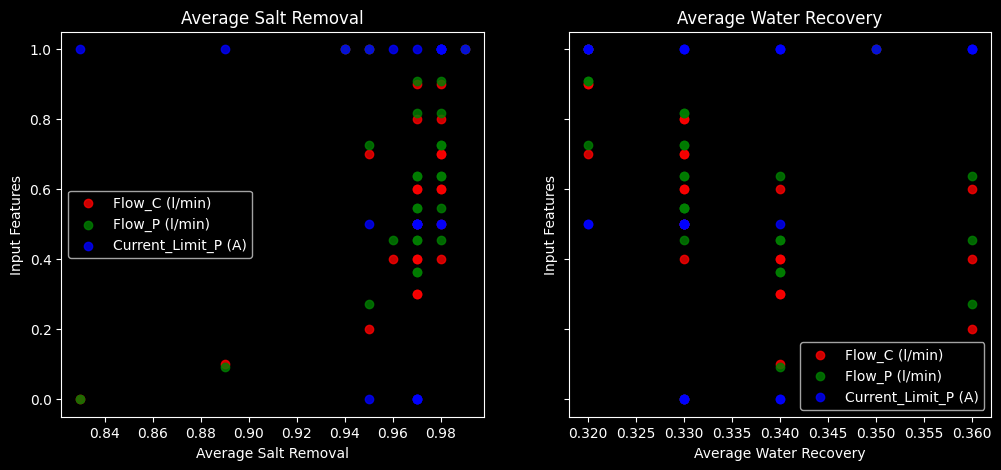

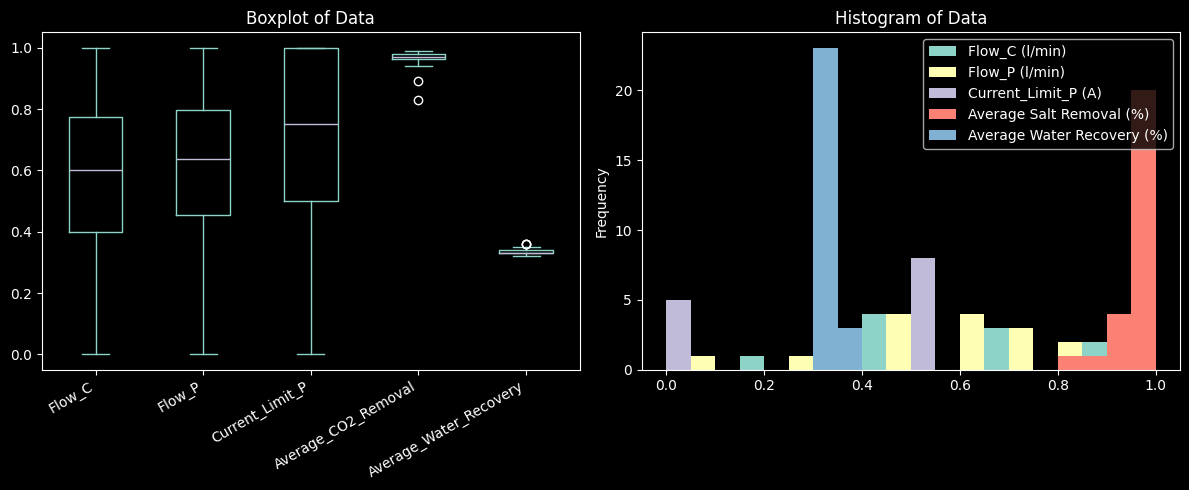

In [ ]:
# Local data frame containing only the relevant columns
df_data_used = df[
    [
        "Series",
        "Measurement",
        "Flow_C (l/min)",
        "Flow_P (l/min)",
        "Current_Limit_P (A)",
        "Average Salt Removal (%)",
        "Average Water Recovery (%)",
    ]
]

# Show statistics of the used data
display(df_data_used.describe().T)

# Scatter plots to visualize relationships between input features and outputs
fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)

axes[0].scatter(
    df_data_used["Average Salt Removal (%)"],
    df_data_used["Flow_C (l/min)"],
    label="Flow_C (l/min)",
    alpha=0.8,
    color="r",
)
axes[0].scatter(
    df_data_used["Average Salt Removal (%)"],
    df_data_used["Flow_P (l/min)"],
    label="Flow_P (l/min)",
    alpha=0.8,
    color="g",
)
axes[0].scatter(
    df_data_used["Average Salt Removal (%)"],
    df_data_used["Current_Limit_P (A)"],
    label="Current_Limit_P (A)",
    alpha=0.8,
    color="b",
)
axes[0].set_xlabel("Average Salt Removal")
axes[0].set_ylabel("Input Features")
axes[0].set_title("Average Salt Removal")
axes[0].legend()

axes[1].scatter(
    df_data_used["Average Water Recovery (%)"],
    df_data_used["Flow_C (l/min)"],
    label="Flow_C (l/min)",
    alpha=0.8,
    color="r",
)
axes[1].scatter(
    df_data_used["Average Water Recovery (%)"],
    df_data_used["Flow_P (l/min)"],
    label="Flow_P (l/min)",
    alpha=0.8,
    color="g",
)
axes[1].scatter(
    df_data_used["Average Water Recovery (%)"],
    df_data_used["Current_Limit_P (A)"],
    label="Current_Limit_P (A)",
    alpha=0.8,
    color="b",
)
axes[1].set_xlabel("Average Water Recovery")
axes[1].set_ylabel("Input Features")
axes[1].set_title("Average Water Recovery")
axes[1].legend()

# Boxplot and histogram to visualize data distribution
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

df_data_used.plot.box(ax=axes[0])
axes[0].set_title("Boxplot of Data")
axes[0].set_xticklabels(
    [
        "Flow_C",
        "Flow_P",
        "Current_Limit_P",
        "Average_CO2_Removal",
        "Average_Water_Recovery",
    ],
    rotation=30,
    ha="right",
    fontsize=10,
)

df_data_used.plot.hist(ax=axes[1], bins=20)
axes[1].set_title("Histogram of Data")

plt.tight_layout()
plt.show()

## Persist preprocessed Data

In the final step, the input and output data must be exported so that it can be reused in modeling and optimization. The data is first exported in CSV file format, but then also stored as numpy arrays in the object cache so that it can be reused directly in other Jupyter Notebooks without intermediate processing. Finally, a check is performed to ensure that the data has been exported correctly by reimporting it.

In [ ]:
# Prepare paths
data_processed_path = os.path.join(
    os.path.dirname(os.getcwd()), "..", "data", "processed"
)
cached_objects_prepared_data_path = os.path.join(
    os.path.dirname(os.getcwd()), "..", "cached_objects", "prepared_data"
)
input_data_path = os.path.join(data_processed_path, "input_data.csv")
output_data_avg_removal_path = os.path.join(
    data_processed_path, "output_data_avg_removal.csv"
)
output_data_avg_recovery_path = os.path.join(
    data_processed_path, "output_data_avg_recovery.csv"
)

# Save processed data in CSV format
df_input_data.to_csv(input_data_path, index=False)
df_output_data_avg_removal.to_csv(output_data_avg_removal_path, index=False)
df_output_data_avg_recovery.to_csv(output_data_avg_recovery_path, index=False)

# Prepare X and y for modelling and optimization
input_columns = ["Flow_C (l/min)", "Flow_P (l/min)", "Current_Limit_P (A)"]
y_label_removal = "Average Salt Removal (%)"
y_label_recovery = "Average Water Recovery (%)"
X = df_input_data[input_columns].values
y_removal = df_output_data_avg_removal[y_label_removal].values
y_recovery = df_output_data_avg_recovery[y_label_recovery].values

joblib.dump(
    y_label_removal,
    os.path.join(cached_objects_prepared_data_path, "y_label_removal.npy"),
)
joblib.dump(
    y_label_recovery,
    os.path.join(cached_objects_prepared_data_path, "y_label_recovery.npy"),
)
joblib.dump(X, os.path.join(cached_objects_prepared_data_path, "X.npy"))
joblib.dump(y_removal, os.path.join(cached_objects_prepared_data_path, "y_removal.npy"))
joblib.dump(
    y_recovery, os.path.join(cached_objects_prepared_data_path, "y_recovery.npy")
)

# Save the scaler for future use
joblib.dump(
    scaler_used_cols, os.path.join(cached_objects_prepared_data_path, "scaler.pkl")
)

['c:\\Users\\david\\HKA-lokal\\5. Semester\\Projektarbeit\\Optimierung\\CapBioCO2_Optimization\\notebooks\\..\\cached_objects\\prepared_data\\scaler.pkl']

In [ ]:
df_read_back_input = pd.read_csv(input_data_path)
df_read_back_output_avg_removal = pd.read_csv(output_data_avg_removal_path)
df_read_back_output_avg_recovery = pd.read_csv(output_data_avg_recovery_path)

display(df_read_back_input.head(3))
display(df_read_back_output_avg_removal.head(3))
display(df_read_back_output_avg_recovery.head(3))

y_label_removal_read_back = joblib.load(
    os.path.join(cached_objects_prepared_data_path, "y_label_removal.npy")
)
y_label_recovery_read_back = joblib.load(
    os.path.join(cached_objects_prepared_data_path, "y_label_recovery.npy")
)
X_read_back = joblib.load(os.path.join(cached_objects_prepared_data_path, "X.npy"))
y_removal_read_back = joblib.load(
    os.path.join(cached_objects_prepared_data_path, "y_removal.npy")
)
y_recovery_read_back = joblib.load(
    os.path.join(cached_objects_prepared_data_path, "y_recovery.npy")
)

display(y_label_removal_read_back)
display(y_label_recovery_read_back)
display(X_read_back[:3])
display(y_removal_read_back[:3])
display(y_recovery_read_back[:3])

scaler_read_back: MinMaxScaler = joblib.load(
    os.path.join(cached_objects_prepared_data_path, "scaler.pkl")
)
X_inv_transform_readback = scaler_read_back.inverse_transform(X_read_back)[0]

display(X_inv_transform_readback[:3])

,Series,Measurement,Flow_C (l/min),Flow_P (l/min),Current_Limit_P (A)
0,1 - Pre-Optimization 0.5,1.1,0.4,0.454545,1.0
1,1 - Pre-Optimization 0.5,1.2,0.2,0.272727,1.0
2,1 - Pre-Optimization 0.5,1.3,0.1,0.090909,1.0


,Series,Measurement,Average Salt Removal (%)
0,1 - Pre-Optimization 0.5,1.1,0.96
1,1 - Pre-Optimization 0.5,1.2,0.95
2,1 - Pre-Optimization 0.5,1.3,0.89


,Series,Measurement,Average Water Recovery (%)
0,1 - Pre-Optimization 0.5,1.1,0.36
1,1 - Pre-Optimization 0.5,1.2,0.36
2,1 - Pre-Optimization 0.5,1.3,0.34


'Average Salt Removal (%)'

'Average Water Recovery (%)'

array([[0.4       , 0.45454545, 1.        ],
       [0.2       , 0.27272727, 1.        ],
       [0.1       , 0.09090909, 1.        ]])

array([0.96, 0.95, 0.89])

array([0.36, 0.36, 0.34])

array([ 0.45,  0.5 , 55.  ])